In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier , plot_tree , export_text
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn. pipeline import Pipeline
from sklearn. preprocessing import StandardScaler
from sklearn. linear_model import LogisticRegression

df = pd.read_csv("loan_approval.csv")
print(df.shape,df["approved"].value_counts().to_dict())

X = df.drop(columns=["approved"])
Y = df["approved"]

X_train, X_test, y_train, y_test = train_test_split(
    X, Y, random_state=42, stratify=Y)

(3000, 7) {1: 1866, 0: 1134}


In [20]:
tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

print('depth :', tree.get_depth())
print('leaves:', tree.get_n_leaves())
train_acc = tree.score(X_train, y_train)
test_acc  = tree.score(X_test, y_test)
print('train :', round(train_acc, 3))
print('test  :', round(test_acc, 3))
print('gap   :', round(train_acc - test_acc, 3))

depth : 22
leaves: 432
train : 1.0
test  : 0.729
gap   : 0.271


## Task 01: Unpruned tree overfits

**Logic:** With no limits the tree keeps splitting until every leaf is pure, so it
memorises the training set.

**Results:** depth = 22, leaves = 432, train = 1.000, test = 0.729, gap = 0.271

**One-line conclusion:** The tree scores 100% on data it has seen but only 72.9% on
new data, and that 27-point train-to-test gap is the definition of overfitting: it
learned the noise of the training sample, not the real pattern.

### Look it up
- **Every leaf has exactly one training point?** The tree has memorised each row.
  It is a lookup table, not a set of rules, and will not generalise.
- **Why is training accuracy 1.0 useless?** Any model can reach 1.0 by memorising.
  It says nothing about unseen data, which is the only thing that matters.
- **Parameters for N leaves?** About 2N-1 nodes: N-1 splits (feature + threshold)
  plus N leaf predictions. Here 432 leaves means ~863 nodes for only 2,250 rows,
  so the tree has nearly as many parameters as the data has rows.

best depth (by test): 3 | test acc: 0.812


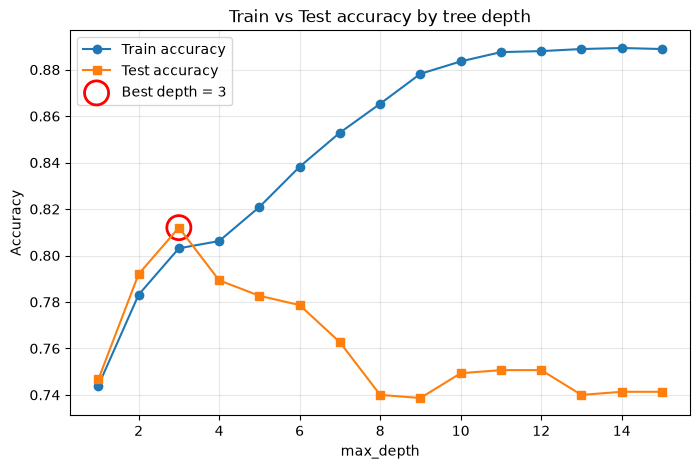

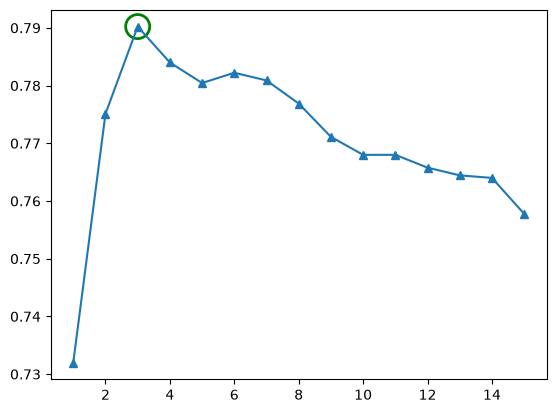

In [21]:
depths = range(1, 16)
tr, te = [], []
for d in depths:
    c = DecisionTreeClassifier(max_depth=d, min_samples_leaf=5,
                               random_state=42).fit(X_train, y_train)
    tr.append(c.score(X_train, y_train))
    te.append(c.score(X_test, y_test))

best = list(depths)[te.index(max(te))]
print('best depth (by test):', best, '| test acc:', round(max(te), 3))

plt.figure(figsize=(8, 5))
plt.plot(depths, tr, marker='o', label='Train accuracy')
plt.plot(depths, te, marker='s', label='Test accuracy')
plt.scatter([best], [max(te)], s=300, facecolors='none',
            edgecolors='red', linewidths=2, label=f'Best depth = {best}')
plt.xlabel('max_depth'); plt.ylabel('Accuracy')
plt.title('Train vs Test accuracy by tree depth')
plt.legend(); plt.grid(alpha=0.3); plt.show()

cv_curve = [scores[d] for d in depths]
plt.plot(depths, cv_curve, marker='^', label='CV mean (train folds)')
plt.scatter([best_d], [scores[best_d]], s=300, facecolors='none',
            edgecolors='green', linewidths=2, label=f'Best CV depth = {best_d}')

## Task 02: max_depth sweep

**Logic:** Fit one tree per depth 1..15 (min_samples_leaf=5) and plot train vs test.
Train keeps rising, test peaks and then falls. The peak is the sweet spot.

**Results:** best depth = 3, test accuracy = 0.812 (train at depth 3 = 0.803).
At depth 15: train = 0.889, test = 0.741.

**Justification:** Below depth 3 the tree is too simple (underfitting: depth 1 gets
0.747). From depth 4 onward the gap opens up, with test falling from 0.812 to
~0.74 while train climbs to 0.889, so the extra splits fit noise. Task 05 confirms
depth 3 using cross-validation, so this choice is not a lucky test split.
(Test being slightly above train at depth 3 is normal sampling noise on 750 rows.)

### Look it up
- **Why does train accuracy rise monotonically?** A deeper tree carves the feature
  space into finer regions, so it can only fit the training data equally well or
  better.
- **Why does test accuracy fall after a certain depth?** Deep splits isolate a few
  points, so they encode quirks of the training sample that don't repeat in new data.
- **min_samples_leaf = 1 or 50?** With 1, leaves can be single points: the train
  curve reaches 1.0 (as in Task 01) and the test curve falls harder. With 50, the
  tree can't get detailed, so it underfits: curves stay close together and train
  accuracy plateaus lower. (With 5, train plateaus at 0.889 because leaves
  need at least 5 rows, so they can't all be pure.)

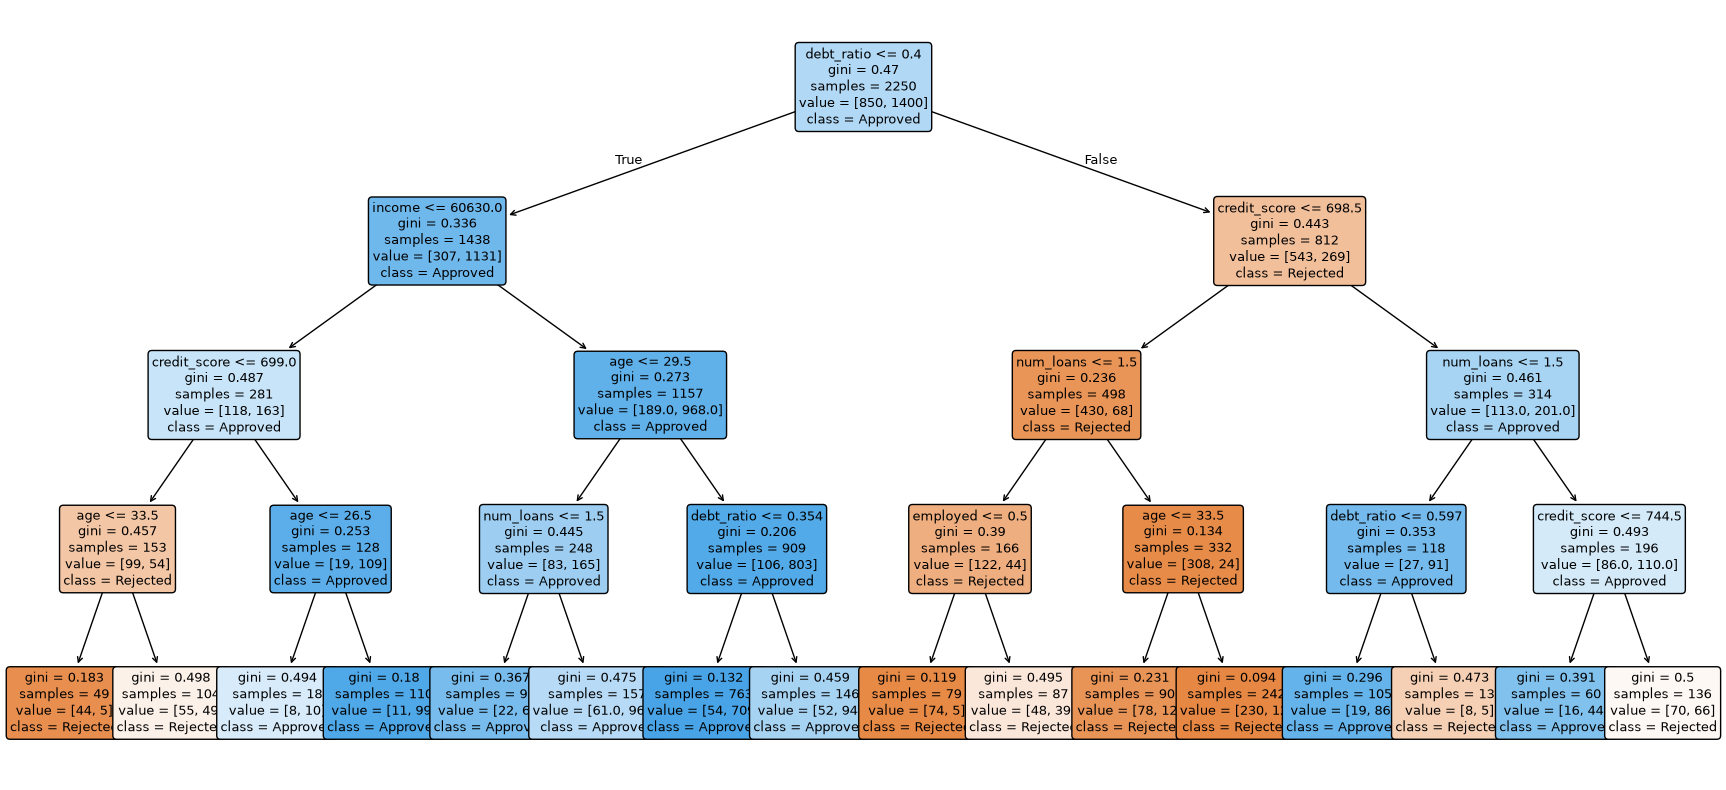

|--- debt_ratio <= 0.40
|   |--- income <= 60630.00
|   |   |--- credit_score <= 699.00
|   |   |   |--- age <= 33.50
|   |   |   |   |--- class: 0
|   |   |   |--- age >  33.50
|   |   |   |   |--- class: 0
|   |   |--- credit_score >  699.00
|   |   |   |--- age <= 26.50
|   |   |   |   |--- class: 1
|   |   |   |--- age >  26.50
|   |   |   |   |--- class: 1
|   |--- income >  60630.00
|   |   |--- age <= 29.50
|   |   |   |--- num_loans <= 1.50
|   |   |   |   |--- class: 1
|   |   |   |--- num_loans >  1.50
|   |   |   |   |--- class: 1
|   |   |--- age >  29.50
|   |   |   |--- debt_ratio <= 0.35
|   |   |   |   |--- class: 1
|   |   |   |--- debt_ratio >  0.35
|   |   |   |   |--- class: 1
|--- debt_ratio >  0.40
|   |--- credit_score <= 698.50
|   |   |--- num_loans <= 1.50
|   |   |   |--- employed <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- employed >  0.50
|   |   |   |   |--- class: 0
|   |   |--- num_loans >  1.50
|   |   |   |--- age <= 33.50
|   |   |   |   |-

In [22]:
pruned = DecisionTreeClassifier(max_depth=4, min_samples_leaf=5,
                                random_state=42).fit(X_train, y_train)

plt.figure(figsize=(22, 10))
plot_tree(pruned, filled=True, rounded=True,
          feature_names=X.columns, class_names=['Rejected', 'Approved'],
          fontsize=9)
plt.show()

print(export_text(pruned, feature_names=list(X.columns)))

## Task 03: Read the tree as rules

**Logic:** A depth-4 tree is small enough to read. Each root-to-leaf path is one
if-then rule. Train accuracy = 0.806, test accuracy = 0.789.

**Top 3 rules (from the printed tree; numbers are rejected/approved training rows):**
1. IF debt_ratio <= 0.35 AND income > 60,630 AND age > 29.5 THEN **Approve**
   (54 rejected / 709 approved, ~93% approved). The biggest, cleanest rule.
2. IF debt_ratio > 0.40 AND credit_score <= 698 AND num_loans >= 2 AND age > 33.5
   THEN **Reject** (230 rejected / 12 approved, ~95% rejected).
3. IF debt_ratio > 0.40 AND credit_score <= 698 AND num_loans <= 1 AND not employed
   THEN **Reject** (74 rejected / 5 approved, ~94% rejected).

*Plain English:* "If you owe little compared to your income, earn a decent amount and
are not very young, approve. If you owe a lot and your credit score is weak, reject,
especially if you already have several loans or no job."
*Hindi:* "Agar karz income ke hisaab se kam hai, income achhi hai aur umar 30 se
upar hai, to loan approve. Agar karz zyada hai aur credit score kamzor hai, to reject."

### Look it up
- **Which two features dominate and why?** debt_ratio is the root split (at 0.40)
  and credit_score is the next big split on the high-debt side (~698). That makes
  sense for a bank: debt_ratio shows whether you *can* repay, credit_score shows
  whether you *have* repaid before.
- **What does `filled=True` do?** It colours each node by its majority class, and
  the darker the shade, the purer the node. Pale or white means a mixed node.
  

debt_ratio      0.511
credit_score    0.294
age             0.069
income          0.064
num_loans       0.037
employed        0.026
dtype: float64
Sum of importances: 1.0


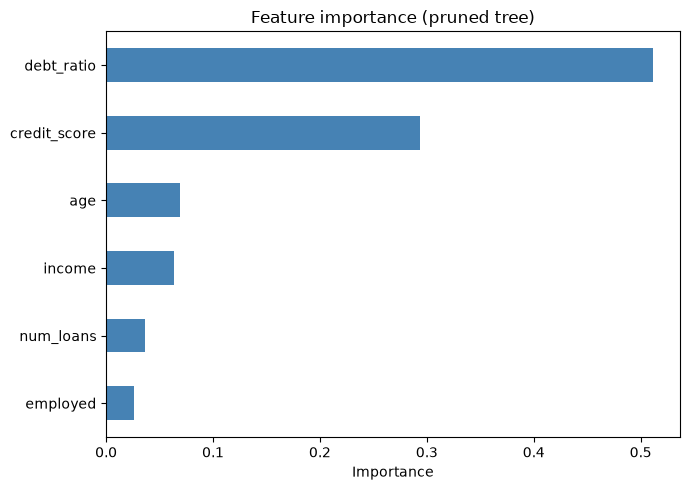

In [23]:
imp = pd.Series(pruned.feature_importances_, index=X.columns).sort_values()

print(imp.sort_values(ascending=False).round(3))
print('Sum of importances:', round(imp.sum(), 3))

imp.plot(kind='barh', figsize=(7, 5), color='steelblue')
plt.xlabel('Importance'); plt.title('Feature importance (pruned tree)')
plt.tight_layout(); plt.show()

## Task 04: Feature importance

**Logic:** `feature_importances_` measures how much each feature reduced Gini
impurity across all splits where it was used, normalised to sum to 1.

**Results:** debt_ratio 0.511, credit_score 0.294, age 0.069, income 0.064,
num_loans 0.037, employed 0.026.

**Reading:** debt_ratio drives approval most (51%) because it is the root split, so it
reduces impurity on all 2,250 rows. credit_score is second (29%). Together they
explain about 80% of the tree's decisions. The other four only refine small subsets.

**Sanity check:** Yes. The top two (debt_ratio, credit_score) match the root and
second-level splits in Task 03.

**Note:** age is not near zero here (0.069), because it appears in several lower
splits. Don't claim "age doesn't matter" without checking; it is small, not zero.

### Look it up
- **What do the values sum to? What does ~0 mean?** They sum to 1. A near-zero score
  means the tree didn't use that feature. It adds little beyond the others, which is
  not proof it is unrelated to the target.
- **Why can importance mislead with correlated features?** If two features carry the
  same information, the tree picks one somewhat arbitrarily and the other looks
  unimportant, or the credit is split. A small data change can flip the winner.

best depth by CV: 3 | CV mean: 0.79
final test accuracy: 0.812


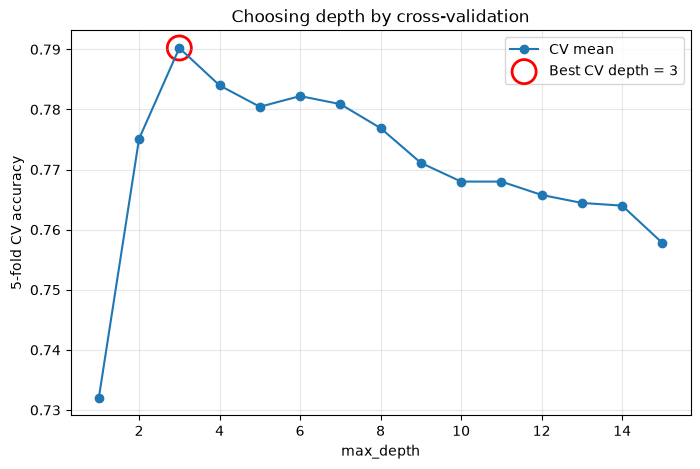

In [24]:
pipe = Pipeline([('tree', DecisionTreeClassifier(min_samples_leaf=5,
                                                  random_state=42))])
scores = {}
for d in range(1, 16):
    pipe.set_params(tree__max_depth=d)
    scores[d] = cross_val_score(pipe, X_train, y_train, cv=5).mean()

best_d = max(scores, key=scores.get)
print('best depth by CV:', best_d, '| CV mean:', round(scores[best_d], 3))

# Final model: fit on train only, touch the test set ONCE
pipe.set_params(tree__max_depth=best_d).fit(X_train, y_train)
print('final test accuracy:', round(pipe.score(X_test, y_test), 3))

plt.figure(figsize=(8, 5))
plt.plot(list(scores.keys()), list(scores.values()), marker='o', label='CV mean')
plt.scatter([best_d], [scores[best_d]], s=300, facecolors='none',
            edgecolors='red', linewidths=2, label=f'Best CV depth = {best_d}')
plt.xlabel('max_depth'); plt.ylabel('5-fold CV accuracy')
plt.title('Choosing depth by cross-validation')
plt.legend(); plt.grid(alpha=0.3); plt.show()

## Task 05: Cross-validation tuning

**Logic:** For each depth, 5-fold CV splits the *training* data into 5 parts, trains
on 4, validates on 1, and averages the 5 scores. Pick the best CV depth, then
evaluate on the test set exactly once.

**Results:** best depth by CV = 3, CV mean = 0.790, final test accuracy = 0.812.
CV curve: depth 1 = 0.732, depth 3 = 0.790, depth 4 = 0.784, depth 15 = 0.758.

**CV vs single split (Task 02):** Both pick depth 3, which is reassuring. The CV mean
(0.790) is ~2 points below the single-split test score (0.812). CV averages 5
validation folds, so it is more stable. The single 750-row test set was a slightly
easy draw. A gap this size is within normal noise. Task 02 chose its depth by
looking at the test set, so only the Task 05 number is an honest estimate.

### Look it up
- **Why is tuning on the test set a mistake?** You pick whatever depth happens to
  score best on that data, so the test score becomes optimistic and stops measuring
  real-world performance (selection leakage).
- **Pre-pruning vs post-pruning?** Pre-pruning stops growth early with limits
  (`max_depth`, `min_samples_leaf`). Post-pruning grows a full tree, then cuts
  weak branches using `cost_complexity_pruning_path` / `ccp_alpha`.

In [25]:
tree_model = DecisionTreeClassifier(max_depth=best_d, min_samples_leaf=5,
                                    random_state=42)
logit_model = Pipeline([('scale', StandardScaler()),
                        ('lr', LogisticRegression(max_iter=1000))])

for name, model in [('Decision Tree', tree_model),
                    ('Logistic Regression', logit_model)]:
    acc = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    auc = cross_val_score(model, X_train, y_train, cv=5, scoring='roc_auc')
    print(f'{name:20s} | CV acc {acc.mean():.3f} | CV AUC {auc.mean():.3f}')

Decision Tree        | CV acc 0.790 | CV AUC 0.824
Logistic Regression  | CV acc 0.740 | CV AUC 0.780


## Task 06: Tree vs linear model

**Logic:** Logistic regression (scaling inside a Pipeline, so it is fit only on each
training fold) vs a pruned tree (depth 3) on raw features, same 5-fold CV.

| Model | CV Accuracy | CV ROC-AUC |
|---|---|---|
| Decision Tree (depth 3) | 0.790 | 0.824 |
| Logistic Regression | 0.740 | 0.780 |

**Verdict:** Yes, the tree earns its place: it beats logistic regression by ~5 points
accuracy and ~4 points AUC, because it captures thresholds and interactions (e.g.
"high debt AND weak credit") that one straight boundary can't. What we traded is
stability and smoothness: a single tree can change a lot if the data shifts, and its
probabilities are coarse (few distinct leaf values).

### Look it up
- **Why do trees need no scaling but logistic regression does?** A tree only asks
  "feature <= threshold?", which depends on ordering, not magnitude. Logistic
  regression uses weighted sums, so large-scale features (income ~ 86,000 vs
  debt_ratio ~ 0.35) dominate and optimisation gets harder.
- **When is a single tree worse than logistic regression?** When the true
  relationship is roughly linear or smooth, when data is small or noisy (trees are
  high-variance), when you need calibrated probabilities, or when you must
  extrapolate beyond the training range.